#  <center>Taller de Aprendizaje Automatico</center>
##  <center>Paso 3: Hacer una exploracion inicial</center>
### <center>Exploracion visual y descriptiva del dataset Higgs Boson</center>

Este notebook se concentra en una exploracion inicial del conjunto de entrenamiento. El objetivo no es entrenar modelos, sino entender mejor la forma de los datos, la variable objetivo, las escalas, los outliers visibles y algunas relaciones potencialmente utiles entre variables y clase.

Como el problema es de clasificacion, se presta especial atencion al balance de clases y a la relacion entre features y `Label`. Para evitar interpretaciones fisicamente incorrectas, los valores `-999` se tratan como marcadores de variables indefinidas y no como mediciones reales cuando se construyen las visualizaciones.

## Carga reproducible de los datos

Se trabaja sobre `training.csv`, que es el unico archivo que contiene la variable objetivo. La celda siguiente localiza la raiz del proyecto y carga el dataset desde `data/higgs-boson/`.

In [1]:
from __future__ import annotations

import os
from pathlib import Path

import numpy as np
import pandas as pd


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raiz del proyecto.")


project_root = find_project_root()
data_dir = project_root / "data" / "higgs-boson"
train_path = data_dir / "training.csv"

if not train_path.exists():
    raise FileNotFoundError(f"No se encontro el archivo esperado: {train_path}")

os.environ["MPLCONFIGDIR"] = str((data_dir / ".mplconfig").resolve())
(data_dir / ".mplconfig").mkdir(exist_ok=True)

from IPython.display import display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

train_data = pd.read_csv(train_path)

print(f"project_root = {project_root}")
print(f"train_path = {train_path}")
print(f"training shape = {train_data.shape}")

project_root = /home/santig14/fing/taa/1_TallerAA
train_path = /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/training.csv
training shape = (250000, 33)


## Preparacion para la exploracion

Las columnas `EventId`, `Weight` y `Label` cumplen un rol especial y no se estudian como features regulares. Para las visualizaciones numericas se reemplaza `-999` por `NaN`, de modo que las graficas no mezclen variables indefinidas con valores fisicos reales.

In [2]:
numeric_feature_columns = train_data.select_dtypes(include="number").columns.difference(["EventId", "Weight"]).tolist()

exploration_data = train_data.copy()
exploration_data[numeric_feature_columns] = exploration_data[numeric_feature_columns].replace(-999, np.nan)
target_numeric = exploration_data["Label"].map({"b": 0, "s": 1})

marker_summary = pd.DataFrame(index=numeric_feature_columns)
marker_summary["minus_999_count"] = train_data[numeric_feature_columns].eq(-999).sum()
marker_summary["minus_999_pct"] = (train_data[numeric_feature_columns].eq(-999).mean() * 100).round(2)
marker_summary = marker_summary[marker_summary["minus_999_count"] > 0].sort_values("minus_999_pct", ascending=False)

display(marker_summary.head(12))
print(f"Cantidad de features numericas analizadas: {len(numeric_feature_columns)}")
print(f"Cantidad de features afectadas por el marcador -999: {len(marker_summary)}")

,minus_999_count,minus_999_pct
DER_deltaeta_jet_jet,177457,70.98
DER_lep_eta_centrality,177457,70.98
DER_mass_jet_jet,177457,70.98
PRI_jet_subleading_pt,177457,70.98
DER_prodeta_jet_jet,177457,70.98
PRI_jet_subleading_phi,177457,70.98
PRI_jet_subleading_eta,177457,70.98
PRI_jet_leading_phi,99913,39.97
PRI_jet_leading_eta,99913,39.97
PRI_jet_leading_pt,99913,39.97


Cantidad de features numericas analizadas: 30
Cantidad de features afectadas por el marcador -999: 11


## Distribucion de la variable objetivo

Antes de mirar relaciones entre variables conviene revisar la distribucion de `Label`. Como se trata de un problema de clasificacion, este paso permite ver si hay balance o desbalance entre `signal` y `background`.

,Label,count,fraction
0,b,164333,0.6573
1,s,85667,0.3427


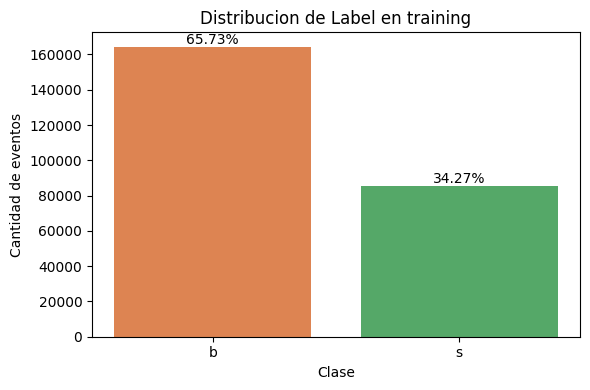

In [3]:
label_counts = train_data["Label"].value_counts().sort_index().rename_axis("Label").reset_index(name="count")
label_counts["fraction"] = (label_counts["count"] / len(train_data)).round(4)
display(label_counts)

fig, ax = plt.subplots(figsize=(6, 4))
colors = {"b": "#DD8452", "s": "#55A868"}
bars = ax.bar(label_counts["Label"], label_counts["count"], color=[colors[label] for label in label_counts["Label"]])
for bar, fraction in zip(bars, label_counts["fraction"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{fraction:.2%}",
        ha="center",
        va="bottom",
        fontsize=10,
    )
ax.set_title("Distribucion de Label en training")
ax.set_xlabel("Clase")
ax.set_ylabel("Cantidad de eventos")
plt.tight_layout()
plt.show()

## Correlacion entre variables numericas

La siguiente matriz de correlacion permite ver que variables numericas tienden a moverse juntas. Para construirla se usan solo las features numericas y se mantiene el mismo criterio del resto del notebook: los valores `-999` ya fueron reemplazados por `NaN`, por lo que no intervienen como si fueran mediciones reales.

,DER_deltaeta_jet_jet,DER_deltar_tau_lep,DER_lep_eta_centrality,DER_mass_MMC,DER_mass_jet_jet,DER_mass_transverse_met_lep,DER_mass_vis,DER_met_phi_centrality,DER_prodeta_jet_jet,DER_pt_h,DER_pt_ratio_lep_tau,DER_pt_tot,DER_sum_pt,PRI_jet_all_pt,PRI_jet_leading_eta,PRI_jet_leading_phi,PRI_jet_leading_pt,PRI_jet_num,PRI_jet_subleading_eta,PRI_jet_subleading_phi,PRI_jet_subleading_pt,PRI_lep_eta,PRI_lep_phi,PRI_lep_pt,PRI_met,PRI_met_phi,PRI_met_sumet,PRI_tau_eta,PRI_tau_phi,PRI_tau_pt
DER_deltaeta_jet_jet,1.000,0.031,0.644,-0.027,0.797,-0.134,-0.039,0.108,-0.836,-0.038,-0.084,-0.148,-0.104,-0.109,-0.002,-0.001,-0.044,-0.175,-0.005,0.001,-0.090,-0.006,0.000,-0.080,-0.059,-0.003,-0.141,-0.004,-0.003,0.018
DER_deltar_tau_lep,0.031,1.000,-0.017,0.497,-0.119,0.043,0.580,-0.205,0.011,-0.539,0.047,-0.148,-0.433,-0.449,-0.000,0.007,-0.484,-0.348,0.002,0.007,-0.232,0.001,-0.001,-0.070,-0.402,-0.002,-0.407,0.004,-0.011,-0.202
DER_lep_eta_centrality,0.644,-0.017,1.000,-0.034,0.478,-0.109,-0.053,0.106,-0.560,0.016,-0.057,-0.122,-0.038,-0.046,0.001,-0.000,0.003,-0.131,0.001,-0.001,-0.027,-0.004,0.000,-0.034,-0.013,0.001,-0.070,-0.002,-0.003,0.037
DER_mass_MMC,-0.027,0.497,-0.034,1.000,-0.022,0.221,0.912,0.020,0.019,0.024,0.071,0.014,0.125,0.011,0.002,0.007,0.006,0.015,0.005,-0.002,-0.016,0.004,-0.003,0.341,0.100,-0.000,0.088,0.003,-0.003,0.266
DER_mass_jet_jet,0.797,-0.119,0.478,-0.022,1.000,-0.132,-0.055,0.151,-0.763,0.189,-0.050,-0.036,0.231,0.240,-0.001,0.001,0.284,-0.074,-0.003,-0.002,0.235,-0.004,-0.004,0.022,0.127,0.001,0.164,-0.006,0.001,0.114
DER_mass_transverse_met_lep,-0.134,0.043,-0.109,0.221,-0.132,1.000,0.190,-0.420,0.124,-0.249,0.350,0.018,-0.147,-0.210,0.000,0.007,-0.146,-0.211,0.002,0.007,-0.036,-0.007,0.000,0.311,0.184,-0.016,-0.168,-0.002,0.001,-0.145
DER_mass_vis,-0.039,0.580,-0.053,0.912,-0.055,0.190,1.000,-0.091,0.033,-0.063,0.097,-0.001,0.089,-0.053,0.003,0.006,-0.076,-0.027,0.002,-0.001,-0.049,0.002,-0.002,0.405,-0.087,-0.001,0.053,0.002,-0.004,0.290
DER_met_phi_centrality,0.108,-0.205,0.106,0.020,0.151,-0.420,-0.091,1.000,-0.115,0.539,-0.039,0.178,0.421,0.452,0.005,0.000,0.270,0.490,-0.004,-0.014,0.092,0.012,0.000,0.054,0.181,0.010,0.423,0.006,-0.002,0.141
DER_prodeta_jet_jet,-0.836,0.011,-0.560,0.019,-0.763,0.124,0.033,-0.115,1.000,-0.026,0.061,0.110,0.014,0.018,-0.004,-0.003,-0.027,0.124,-0.003,0.002,0.003,0.004,0.000,0.039,0.010,0.003,0.047,0.004,0.001,-0.041
DER_pt_h,-0.038,-0.539,0.016,0.024,0.189,-0.249,-0.063,0.539,-0.026,1.000,0.089,0.311,0.833,0.809,0.003,0.001,0.826,0.623,0.000,-0.008,0.360,0.008,-0.003,0.361,0.680,0.009,0.783,0.002,0.005,0.407


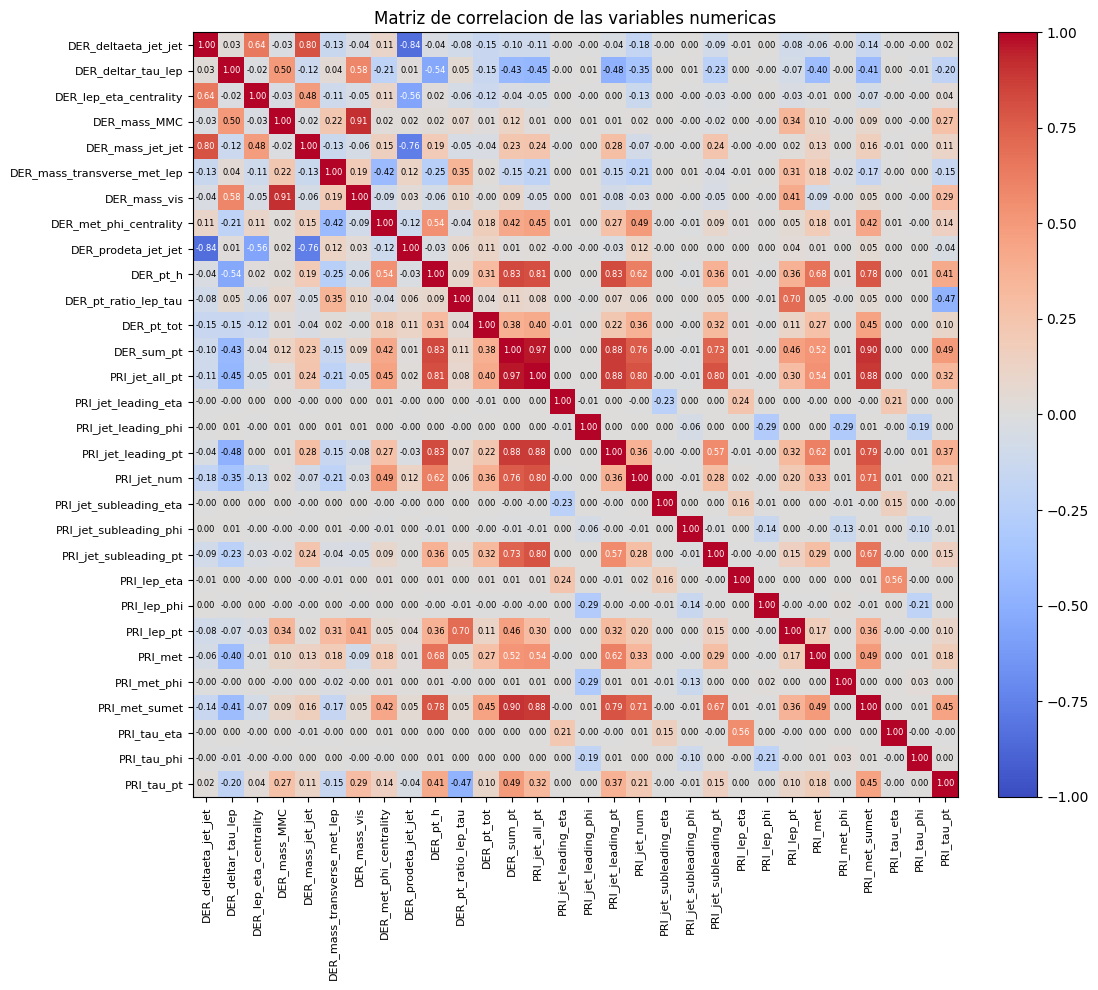

In [4]:
corr_matrix = exploration_data[numeric_feature_columns].corr()

display(corr_matrix.round(3))

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_xticklabels(corr_matrix.columns, rotation=90, fontsize=8)
ax.set_yticklabels(corr_matrix.index, fontsize=8)

for row in range(len(corr_matrix.index)):
    for column in range(len(corr_matrix.columns)):
        value = corr_matrix.iloc[row, column]
        text_color = "white" if abs(value) >= 0.5 else "black"
        ax.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=6,
            color=text_color,
        )
ax.set_title("Matriz de correlacion de las variables numericas")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## Correlacion de las features con Label

Para mirar solo la relacion entre cada feature y la clase, se codifica `Label` como una variable binaria (`b = 0`, `s = 1`) y se calcula la correlacion de cada feature numerica con esa columna. Esto no implica causalidad ni importancia final del modelo, pero sirve como una primera lectura ordenada de que variables parecen mas asociadas a la clase. En esta vista se excluyen las features con mas de `70%` de valores nulos, para que el ranking no quede dominado por columnas demasiado incompletas.

,corr_with_label,null_pct
DER_mass_transverse_met_lep,-0.351,0.00
DER_met_phi_centrality,0.272,0.00
PRI_tau_pt,0.235,0.00
DER_pt_ratio_lep_tau,-0.195,0.00
DER_pt_h,0.193,0.00
DER_sum_pt,0.153,0.00
PRI_met_sumet,0.136,0.00
PRI_jet_all_pt,0.134,0.00
PRI_jet_num,0.134,0.00
PRI_jet_leading_pt,0.109,39.97


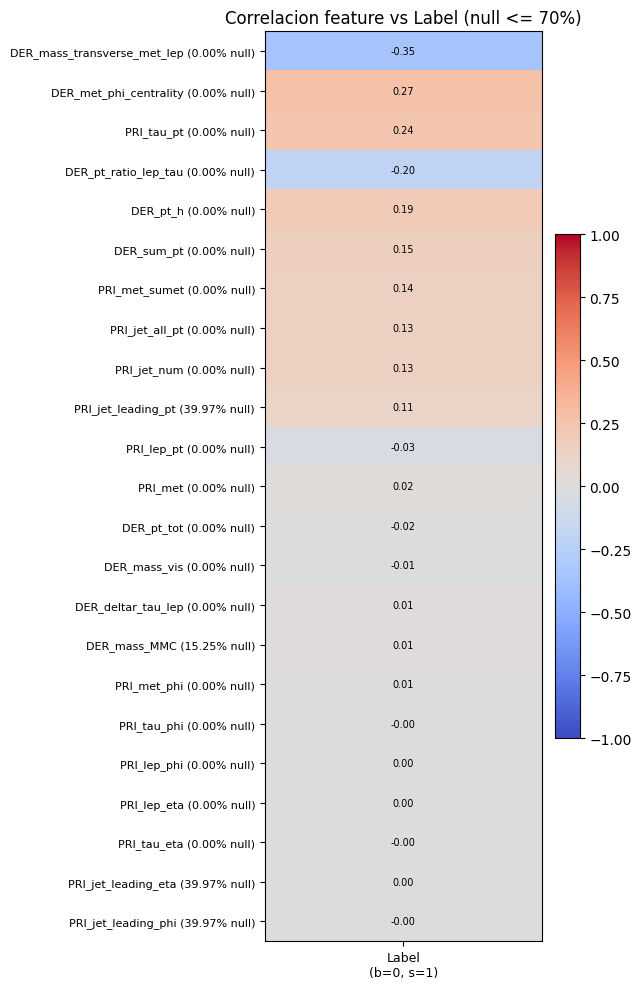

In [5]:
label_corr = exploration_data[numeric_feature_columns].corrwith(target_numeric).sort_values(
    key=lambda series: series.abs(),
    ascending=False,
)
label_corr_frame = label_corr.to_frame(name="corr_with_label")
label_corr_frame["null_pct"] = (
    exploration_data[numeric_feature_columns].isna().mean().mul(100).reindex(label_corr_frame.index).round(2)
)
label_corr_frame = label_corr_frame[label_corr_frame["null_pct"] <= 70].copy()

display(label_corr_frame.round(3))

fig, ax = plt.subplots(figsize=(6.5, 10))
im = ax.imshow(label_corr_frame[["corr_with_label"]].values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks([0])
ax.set_xticklabels(["Label\n(b=0, s=1)"], fontsize=9)
ax.set_yticks(range(len(label_corr_frame.index)))
ax.set_yticklabels(
    [f"{feature} ({null_pct:.2f}% null)" for feature, null_pct in zip(label_corr_frame.index, label_corr_frame["null_pct"])],
    fontsize=8,
)

for row, value in enumerate(label_corr_frame["corr_with_label"]):
    text_color = "white" if abs(value) >= 0.5 else "black"
    ax.text(
        0,
        row,
        f"{value:.2f}",
        ha="center",
        va="center",
        fontsize=7,
        color=text_color,
    )

ax.set_title("Correlacion feature vs Label (null <= 70%)")
fig.colorbar(im, ax=ax, fraction=0.08, pad=0.04)
plt.tight_layout()
plt.show()

## Correlacion de las features con Weight

Esta vista repite la misma idea, pero usando `Weight`. Se incluye solo como inspeccion descriptiva, porque `Weight` es una columna especial del challenge y no debe usarse como feature del clasificador. Aun asi, mirar estas correlaciones sirve para entender mejor el rol particular que tiene esa columna en el dataset.

,corr_with_weight
PRI_jet_num,-0.495
DER_met_phi_centrality,-0.472
PRI_met_sumet,-0.427
PRI_jet_all_pt,-0.420
DER_mass_transverse_met_lep,0.420
DER_sum_pt,-0.415
DER_pt_h,-0.414
PRI_tau_pt,-0.285
DER_deltaeta_jet_jet,-0.277
DER_mass_jet_jet,-0.277


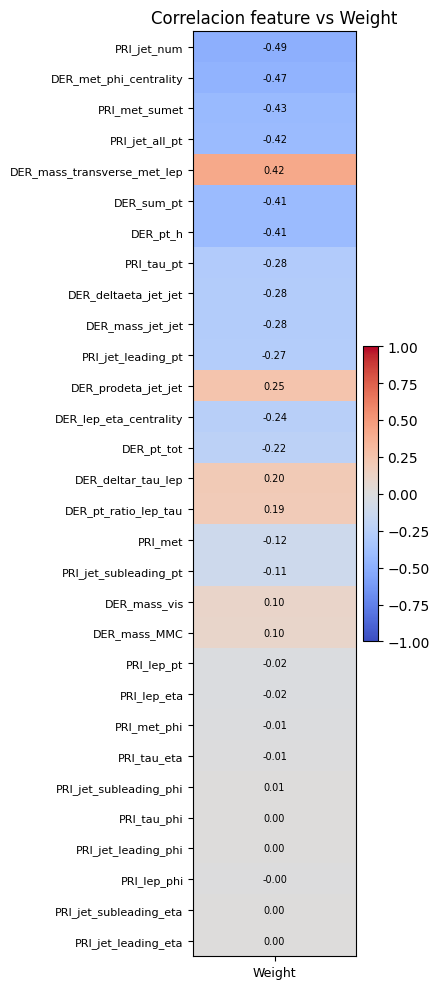

In [6]:
weight_corr = exploration_data[numeric_feature_columns].corrwith(train_data["Weight"]).sort_values(
    key=lambda series: series.abs(),
    ascending=False,
)
weight_corr_frame = weight_corr.to_frame(name="corr_with_weight")

display(weight_corr_frame.round(3))

fig, ax = plt.subplots(figsize=(4.5, 10))
im = ax.imshow(weight_corr_frame.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks([0])
ax.set_xticklabels(["Weight"], fontsize=9)
ax.set_yticks(range(len(weight_corr_frame.index)))
ax.set_yticklabels(weight_corr_frame.index, fontsize=8)

for row, value in enumerate(weight_corr_frame["corr_with_weight"]):
    text_color = "white" if abs(value) >= 0.5 else "black"
    ax.text(
        0,
        row,
        f"{value:.2f}",
        ha="center",
        va="center",
        fontsize=7,
        color=text_color,
    )

ax.set_title("Correlacion feature vs Weight")
fig.colorbar(im, ax=ax, fraction=0.08, pad=0.04)
plt.tight_layout()
plt.show()

## Estudio inicial de outliers

En este contexto, un valor extremo no necesariamente significa un dato erroneo. Puede ser simplemente un evento raro pero valido desde el punto de vista fisico. Por eso, esta seccion usa un criterio descriptivo y conservador: para cada feature con hasta `70%` de valores nulos, se marcan como outliers los valores que quedan fuera del rango `[Q1 - 1.5 * IQR, Q3 + 1.5 * IQR]`. La idea es detectar variables con colas largas o dispersion inusualmente alta, no descartar observaciones. Ademas, para cada feature se resume que proporcion de esos outliers pertenece a `b` y que proporcion pertenece a `s`.

,feature,null_pct,outlier_pct,lower_fence,upper_fence,n_valid,b_pct,s_pct
1,DER_mass_MMC,15.25,6.354,26.490,200.877,211886,95.05,4.95
12,PRI_jet_leading_pt,39.97,5.925,-43.957,191.721,150087,51.75,48.25
3,DER_mass_vis,0.00,5.844,10.083,141.564,250000,95.97,4.03
22,PRI_tau_pt,0.00,5.570,-6.046,75.655,250000,45.64,54.36
5,DER_pt_h,0.00,5.556,-83.582,176.819,250000,43.37,56.63
16,PRI_lep_pt,0.00,5.374,0.852,84.912,250000,67.64,32.36
17,PRI_met,0.00,5.320,-24.348,97.640,250000,49.86,50.14
8,DER_sum_pt,0.00,4.916,-106.842,384.871,250000,56.74,43.26
9,PRI_jet_all_pt,0.00,4.461,-164.901,274.834,250000,60.28,39.72
19,PRI_met_sumet,0.00,4.123,-87.525,473.922,250000,60.01,39.99


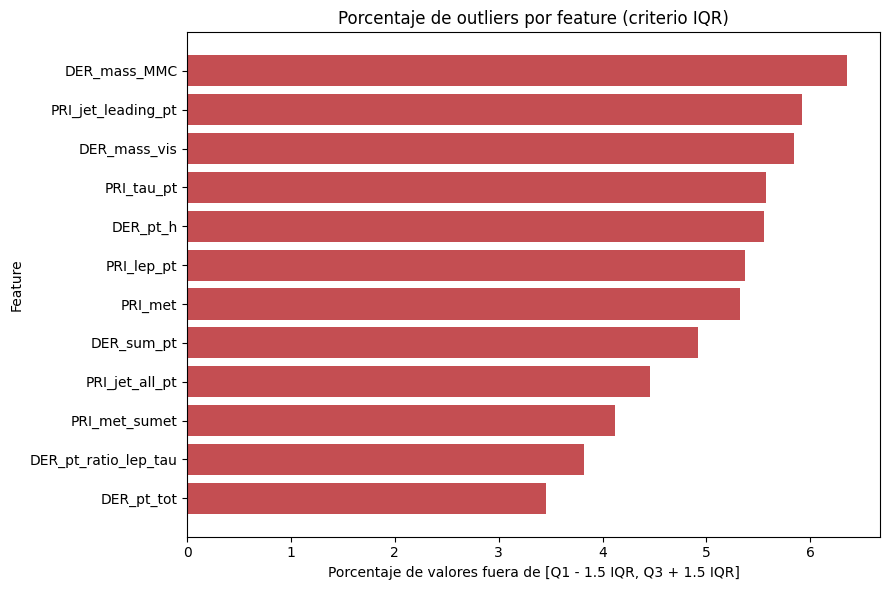

In [7]:
eligible_outlier_columns = [
    column for column in numeric_feature_columns
    if exploration_data[column].isna().mean() * 100 <= 70
]

outlier_rows = []
for column in eligible_outlier_columns:
    values = exploration_data[column].dropna()
    if len(values) < 10:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    if pd.isna(iqr) or iqr == 0:
        continue

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outlier_mask = (values < lower_fence) | (values > upper_fence)
    label_mix = (
        train_data.loc[values.index, "Label"][outlier_mask]
        .value_counts(normalize=True)
        .mul(100)
        .reindex(["b", "s"], fill_value=0)
        .round(2)
    )

    outlier_rows.append(
        {
            "feature": column,
            "null_pct": round(exploration_data[column].isna().mean() * 100, 2),
            "outlier_pct": round(outlier_mask.mean() * 100, 3),
            "lower_fence": round(lower_fence, 3),
            "upper_fence": round(upper_fence, 3),
            "n_valid": int(len(values)),
            "b_pct": float(label_mix["b"]),
            "s_pct": float(label_mix["s"]),
        }
    )

outlier_summary = pd.DataFrame(outlier_rows).sort_values("outlier_pct", ascending=False)
display(outlier_summary.head(12))

fig, ax = plt.subplots(figsize=(9, 6))
top_outlier_summary = outlier_summary.head(12).sort_values("outlier_pct")
ax.barh(top_outlier_summary["feature"], top_outlier_summary["outlier_pct"], color="#C44E52")
ax.set_title("Porcentaje de outliers por feature (criterio IQR)")
ax.set_xlabel("Porcentaje de valores fuera de [Q1 - 1.5 IQR, Q3 + 1.5 IQR]")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

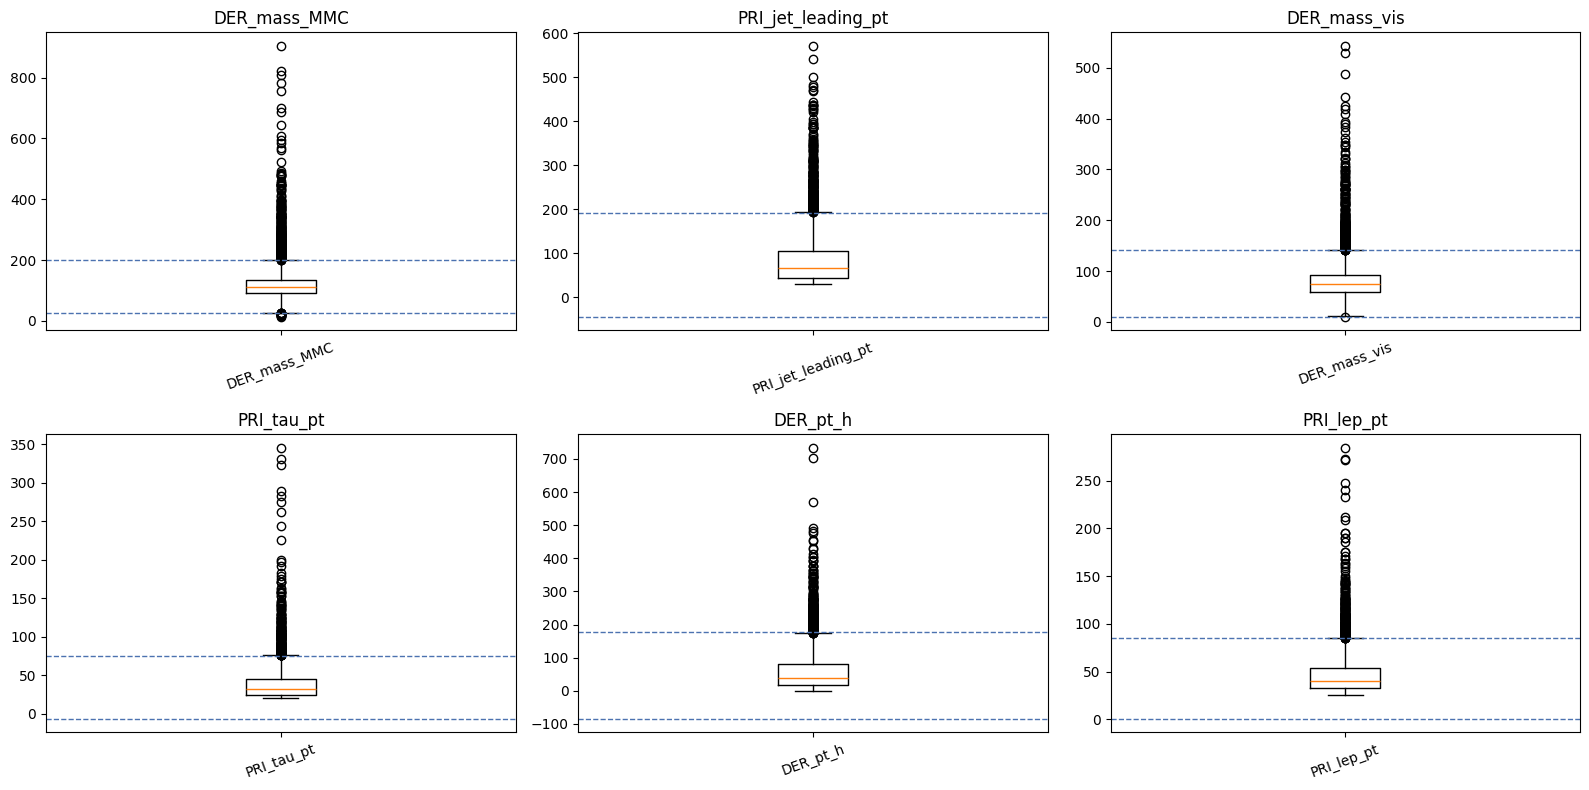

In [8]:
top_outlier_features = outlier_summary.head(6)["feature"].tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, column in zip(axes.ravel(), top_outlier_features):
    values = exploration_data[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    sample = values
    if len(sample) > 5000:
        sample = sample.sample(n=5000, random_state=42)

    ax.boxplot(sample, tick_labels=[column], showfliers=True)
    ax.axhline(lower_fence, color="#4C72B0", linestyle="--", linewidth=1)
    ax.axhline(upper_fence, color="#4C72B0", linestyle="--", linewidth=1)
    ax.set_title(column)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## Ejemplos concretos de outliers

Para aterrizar el resumen anterior en casos reales, en esta seccion se muestran ejemplos concretos de outliers para algunas de las features con mayor `outlier_pct`. En cada caso se listan eventos del dataset con su `EventId`, su clase `Label`, el valor de la feature y si el valor extremo cae por debajo (`low`) o por encima (`high`) de las cercas definidas por el criterio IQR.

In [9]:
example_outlier_features = outlier_summary.head(4)["feature"].tolist()

for feature in example_outlier_features:
    feature_row = outlier_summary.loc[outlier_summary["feature"] == feature].iloc[0]
    lower_fence = feature_row["lower_fence"]
    upper_fence = feature_row["upper_fence"]

    feature_examples = train_data[["EventId", "Label"]].copy()
    feature_examples[feature] = exploration_data[feature]
    feature_examples = feature_examples.dropna(subset=[feature]).copy()
    feature_examples = feature_examples[
        (feature_examples[feature] < lower_fence) | (feature_examples[feature] > upper_fence)
    ].copy()
    feature_examples["outlier_side"] = np.where(
        feature_examples[feature] < lower_fence,
        "low",
        "high",
    )
    feature_examples["distance_to_fence"] = np.where(
        feature_examples["outlier_side"] == "low",
        lower_fence - feature_examples[feature],
        feature_examples[feature] - upper_fence,
    )
    feature_examples = feature_examples.sort_values("distance_to_fence", ascending=False)
    label_mix = feature_examples["Label"].value_counts(normalize=True).mul(100).reindex(["b", "s"], fill_value=0).round(2)

    print(f"\nFeature: {feature}")
    print(
        f"Lower fence = {lower_fence:.3f} | Upper fence = {upper_fence:.3f} | "
        f"Outlier pct = {feature_row['outlier_pct']:.3f}%"
    )
    print(f"Outliers con Label b = {label_mix['b']:.2f}% | Label s = {label_mix['s']:.2f}%")
    display(feature_examples.head(8).reset_index(drop=True))


Feature: DER_mass_MMC
Lower fence = 26.490 | Upper fence = 200.877 | Outlier pct = 6.354%
Outliers con Label b = 95.05% | Label s = 4.95%


,EventId,Label,DER_mass_MMC,outlier_side,distance_to_fence
0,251832,b,1192.026,high,991.149
1,284836,b,988.199,high,787.322
2,289825,b,987.561,high,786.684
3,218612,b,985.102,high,784.225
4,182064,b,980.192,high,779.315
5,283650,b,977.515,high,776.638
6,178155,s,977.333,high,776.456
7,313921,b,970.416,high,769.539



Feature: PRI_jet_leading_pt
Lower fence = -43.957 | Upper fence = 191.721 | Outlier pct = 5.925%
Outliers con Label b = 51.75% | Label s = 48.25%


,EventId,Label,PRI_jet_leading_pt,outlier_side,distance_to_fence
0,168117,b,1120.573,high,928.852
1,253775,b,760.846,high,569.125
2,140226,b,755.235,high,563.514
3,244424,b,743.222,high,551.501
4,190250,s,738.235,high,546.514
5,273649,b,720.282,high,528.561
6,249711,b,703.516,high,511.795
7,245654,s,693.377,high,501.656



Feature: DER_mass_vis
Lower fence = 10.083 | Upper fence = 141.564 | Outlier pct = 5.844%
Outliers con Label b = 95.97% | Label s = 4.03%


,EventId,Label,DER_mass_vis,outlier_side,distance_to_fence
0,302795,b,1349.351,high,1207.787
1,232402,b,1329.913,high,1188.349
2,184175,b,1153.166,high,1011.602
3,149297,b,1051.358,high,909.794
4,175797,b,1034.205,high,892.641
5,251832,b,959.601,high,818.037
6,218381,b,922.885,high,781.321
7,289825,b,798.219,high,656.655



Feature: PRI_tau_pt
Lower fence = -6.046 | Upper fence = 75.655 | Outlier pct = 5.570%
Outliers con Label b = 45.64% | Label s = 54.36%


,EventId,Label,PRI_tau_pt,outlier_side,distance_to_fence
0,302795,b,764.408,high,688.753
1,291362,s,622.862,high,547.207
2,324880,b,505.060,high,429.405
3,278234,b,449.648,high,373.993
4,338297,s,415.985,high,340.330
5,141158,b,396.875,high,321.220
6,182596,b,389.958,high,314.303
7,118323,b,384.756,high,309.101
